In [14]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data/preprocessed")
if not data_dir.exists():
    data_dir = Path("Tweet-Emotion-Detection/data/preprocessed")

train_df = pd.read_csv(data_dir / "train.csv")
val_df = pd.read_csv(data_dir / "validation.csv")
test_df = pd.read_csv(data_dir / "test.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

train_df.head()

Train: (3257, 2)
Validation: (374, 2)
Test: (1421, 2)


,clean_text,label
0,worry payment problem may never joyce meyer mo...,2
1,roommate okay cannot spell autocorrect terribl...,0
2,no cute atsu probably shy photo cherry help uwu,1
3,rooneys fuck untouchable not fuck dreadful dep...,0
4,pretty depress hit pan favourite highlighter,3


In [2]:
print(train_df["label"].value_counts())

label
0    1400
3     855
1     708
2     294
Name: count, dtype: int64


In [3]:
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer

# Reload all splits here so stale notebook variables cannot hide clean_text.
data_dir = Path("../data/preprocessed")
if not data_dir.exists():
    data_dir = Path("Tweet-Emotion-Detection/data/preprocessed")

train_df = pd.read_csv(data_dir / "train.csv")
val_df = pd.read_csv(data_dir / "validation.csv")
test_df = pd.read_csv(data_dir / "test.csv")

X_train = train_df["clean_text"].fillna("")
y_train = train_df["label"]

X_val = val_df["clean_text"].fillna("")
y_val = val_df["label"]

X_test = test_df["clean_text"].fillna("")
y_test = test_df["label"]

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 1),
    min_df=1,
    max_df=1.0
)

# Fit ONLY on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and test data
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Validation data shape:", X_val_tfidf.shape)
print("Test data shape:", X_test_tfidf.shape)

Training data shape: (3257, 8227)
Validation data shape: (374, 8227)
Test data shape: (1421, 8227)


In [13]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    max_iter=2000,
    random_state=42
)

log_reg.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=2000, random_state=42)

In [11]:
from sklearn.metrics import accuracy_score, classification_report

val_predictions = log_reg.predict(X_val_tfidf)

print("Validation Accuracy:", accuracy_score(y_val, val_predictions))

print("\nClassification Report:")
print(classification_report(y_val, val_predictions))

ValueError: X has 8227 features, but LogisticRegression is expecting 6328 features as input.

In [7]:
test_predictions = log_reg.predict(X_test_tfidf)

print("Test Accuracy:", accuracy_score(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions))

Test Accuracy: 0.6783954961294862

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.89      0.74       558
           1       0.73      0.59      0.65       358
           2       0.67      0.15      0.24       123
           3       0.73      0.63      0.67       382

    accuracy                           0.68      1421
   macro avg       0.69      0.56      0.58      1421
weighted avg       0.69      0.68      0.66      1421



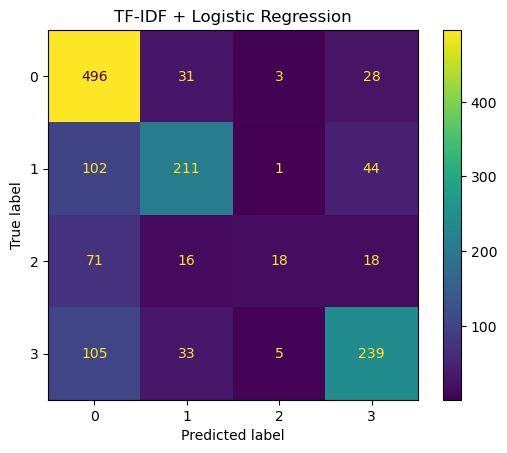

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, test_predictions)

display = ConfusionMatrixDisplay(confusion_matrix=cm)

display.plot()
plt.title("TF-IDF + Logistic Regression")
plt.show()

In [9]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_val, val_predictions))
print(confusion_matrix(y_val, val_predictions))

              precision    recall  f1-score   support

           0       0.64      0.88      0.74       160
           1       0.73      0.56      0.63        97
           2       1.00      0.14      0.25        28
           3       0.71      0.62      0.66        89

    accuracy                           0.68       374
   macro avg       0.77      0.55      0.57       374
weighted avg       0.71      0.68      0.66       374

[[140  12   0   8]
 [ 32  54   0  11]
 [ 17   4   4   3]
 [ 30   4   0  55]]
